# 01: Testing the dataset claims

The dataset evaluation report makes claims about each dataset. This notebook checks them against the data, one claim at a time.

Each section has the same four parts:
- **Claim:** what the report says
- **Check:** the code
- **Result:** one small table or chart
- **Verdict:** confirmed, partly true, or wrong

No models are trained here. Notebook 02 tests whether these flaws affect a model.

**Data used**

| Dataset | Files | Where they came from |
|---|---|---|
| UNSW-NB15 | training and testing CSVs | official download (identical to the official files byte for byte) |
| UNSW-NB15 | creators' Zeek `conn.log` files, labelled from the ground-truth table | official download, built by `colab_scripts/colab_unsw_official_zeek.py` |
| UWF-ZeekData | the 24, Fall24-2, Sum25-1 and Sum25-2 releases | official site (datasets.uwf.edu) |
| CIC-IDS2017 | packet captures converted to Zeek | **HuggingFace mirror** (`bvsam/cic-ids-2017`); the official download needs a registration form, so this copy is unverified |

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd

from cybershield.ml.zeek_features import DATASETS_DIR, load_cic2017_zeek, load_unsw_official_zeek

pct = lambda x: f"{x:.1%}"
train = pd.read_csv(DATASETS_DIR / "unsw_nb15/UNSW_NB15_training-set.csv")
test = pd.read_csv(DATASETS_DIR / "unsw_nb15/UNSW_NB15_testing-set.csv")
features = [c for c in train.columns if c not in ("id", "label", "attack_cat")]
unsw = load_unsw_official_zeek(with_features=False)

## Part A: UNSW-NB15 training and testing CSVs

### A1. One TTL value separates attacks from normal traffic

**Claim:** In the training CSV, 87% of attack rows have a TTL of exactly 254, compared with only 20% of normal rows.

In [2]:
pd.DataFrame({
    "Rows with TTL = 254": {
        "Attack rows": pct((train.loc[train.label == 1, "sttl"] == 254).mean()),
        "Normal rows": pct((train.loc[train.label == 0, "sttl"] == 254).mean()),
    }
})

,Rows with TTL = 254
Attack rows,86.7%
Normal rows,20.1%


**Verdict: confirmed.** One exact TTL value marks most attacks and few normal rows. Notebook 02 (experiment 1) tests how far a model gets with TTL alone.

### A2. Many rows are duplicates

**Claim:** 42% of training rows are duplicates [Al-Daweri et al.], and so are 34.5% of testing rows.

Two ways to count a duplicate: rows identical in their **features** (ignoring the row id and the label), or identical in **every column**.

In [3]:
def dup_share(df, cols):
    return pct(df[cols].duplicated().mean())

pd.DataFrame({
    "Identical features": {"Training CSV": dup_share(train, features), "Testing CSV": dup_share(test, features)},
    "Identical in every column": {"Training CSV": dup_share(train, features + ["label", "attack_cat"]),
                                  "Testing CSV": dup_share(test, features + ["label", "attack_cat"])},
})

,Identical features,Identical in every column
Training CSV,42.4%,38.6%
Testing CSV,34.5%,32.0%


**Verdict: confirmed, with a definition.** The report's figures (42% and 34.5%) count rows with identical features. Counting identical full rows gives 39% and 32%. Al-Daweri et al. reported no duplicates in the testing CSV; the data shows otherwise.

### A3. The training and testing CSVs don't match

**Claim:** The training CSV is 32% normal and the testing CSV is 45%. And 20% of normal rows have a TTL of exactly 254 in training, compared with 41% in testing.

In [4]:
pd.DataFrame({
    "Normal share of rows": {"Training CSV": pct((train.label == 0).mean()), "Testing CSV": pct((test.label == 0).mean())},
    "Normal rows with TTL = 254": {"Training CSV": pct((train.loc[train.label == 0, "sttl"] == 254).mean()),
                                    "Testing CSV": pct((test.loc[test.label == 0, "sttl"] == 254).mean())},
})

,Normal share of rows,Normal rows with TTL = 254
Training CSV,31.9%,20.1%
Testing CSV,44.9%,40.7%


**Verdict: confirmed.** The testing CSV has more normal traffic, and twice as many of its normal rows carry the "attack" TTL value. Notebook 02 shows what this does to false alarms.

### A4. The "Generic" class is mostly DNS

**Claim:** The "Generic" attack class is officially defined as attacks on encryption, but Flood et al. found it consists mostly of DNS records.

In [5]:
generic = train[train.attack_cat == "Generic"]
pd.DataFrame({
    "Value": {
        "Generic rows in the training CSV": f"{len(generic):,}",
        "Share of all attacks": pct(len(generic) / (train.label == 1).sum()),
        "Generic rows that are DNS": pct((generic.service == "dns").mean()),
    }
})

,Value
Generic rows in the training CSV,"40,000"
Share of all attacks,33.5%
Generic rows that are DNS,97.8%


**Verdict: confirmed.** Almost all Generic rows are DNS, and the class is a third of the training CSV's attacks.

## Part B: UNSW-NB15's own Zeek logs

The official download includes the creators' Zeek `conn.log` files. We labelled each connection from the official ground-truth table: same addresses, ports and protocol, starting within the attack's time (±1 second). Everything else is normal.

### B1. The logs are standard Zeek, but have gaps

**Claim:** The logs have every field of today's Zeek `conn.log` except two minor ones. One log is missing and one is broken.

In [6]:
summary = json.loads((DATASETS_DIR / "unsw_official/summary.json").read_text())
parts = pd.read_csv(DATASETS_DIR / "unsw_official/parts.csv")
parts["start (UTC)"] = pd.to_datetime(parts.ts_min, unit="s").dt.strftime("%H:%M")
parts["end (UTC)"] = pd.to_datetime(parts.ts_max, unit="s").dt.strftime("%H:%M")

print("Fields missing compared with current Zeek:", summary["current_zeek_fields_missing"])
print("Day 1 parts present:", sorted(parts.loc[parts.day == "D1", "part"].tolist()))
parts.loc[parts.day == "D1", ["part", "rows", "start (UTC)", "end (UTC)", "oth_share", "repeated_5tuple_share", "kept"]]

Fields missing compared with current Zeek: ['local_resp', 'ip_proto']
Day 1 parts present: [1, 2, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18]


,part,rows,start (UTC),end (UTC),oth_share,repeated_5tuple_share,kept
0,1,58174,11:49,12:30,0.000344,0.001788,True
1,2,57265,12:30,13:10,0.001991,0.001834,True
2,4,59751,13:52,14:37,0.001908,0.000385,True
3,5,57109,14:37,15:23,0.001786,0.000385,True
4,6,59822,15:23,16:10,0.002123,0.000284,True
5,7,55785,16:10,16:54,0.001667,0.000269,True
6,8,56644,16:54,17:38,0.001059,0.000177,True
7,9,58853,17:38,18:22,0.001903,0.000238,True
8,10,55979,18:22,19:04,0.001572,0.000197,True
9,11,1796336,16:40,19:49,0.920356,0.960594,False


**Verdict: confirmed.**
- Only `local_resp` and `ip_proto` are missing.
- Part 3 of Day 1 has no log, which leaves a gap from 13:10 to 13:52.
- Part 11 overlaps parts 7–10 in time. Most of its rows are single packets with no handshake (`OTH`), and most repeat the same addresses and ports. It was dropped.
- Part 18 overlaps other parts; its duplicate rows were removed.

### B2. Labelling works, but not fully

**Claim:** Our labels match the creators' own labels. Most TCP attacks are found in the logs, but many UDP attacks aren't.

In [7]:
gt = pd.read_parquet(DATASETS_DIR / "unsw_official/gt.parquet")
gt["protocol"] = gt.proto.where(gt.proto.isin(["tcp", "udp"]), "other (OSPF, SCTP, ...)")
coverage = gt.groupby("protocol").matched.agg(["size", "mean"]).rename(columns={"size": "attacks in ground truth", "mean": "found in the logs"})
coverage["found in the logs"] = coverage["found in the logs"].map(pct)

print(f"Connections: {len(unsw):,}   labelled as attacks: {unsw.label.sum():,} ({pct(unsw.label.mean())})")
print(f"Agreement with the creators' labels in the full CSVs: {pct(summary['label_agreement_with_full_csv'])} "
      f"(on the {summary['conn_rows_matched_to_full_csv']:,} connections that matched a CSV record)")
coverage

Connections: 1,922,568   labelled as attacks: 63,741 (3.3%)
Agreement with the creators' labels in the full CSVs: 100.0% (on the 1,874,712 connections that matched a CSV record)


,attacks in ground truth,found in the logs
protocol,,
"other (OSPF, SCTP, ...)",90673,0.0%
tcp,56596,95.1%
udp,27078,47.4%


**Verdict: confirmed.**
- Our labels agree with the creators' labels wherever both exist. The creators built theirs from the same ground-truth table, so this shows our matching reproduces theirs, not that the labels are correct.
- 95% of TCP attacks are found, but under half of UDP attacks.
- Protocols other than TCP and UDP are never found, because `conn.log` doesn't record them as connections.

### B3. The capture is shorter than described, and Day 1 has an attack-free period

**Claim:** The paper describes 16 hours on Day 1 and 15 on Day 2. The logs cover about 12.6 and 12.1 hours. On Day 1, all attacks fall between 11:50 and 13:47 UTC (Lanvin et al. say there is no attack-free period).

Hours covered by the logs: {'D1': '12.6 h', 'D2': '12.1 h'}
Day 1 attacks in the ground truth: 2015-01-22 11:50:14 to 2015-01-22 13:47:28


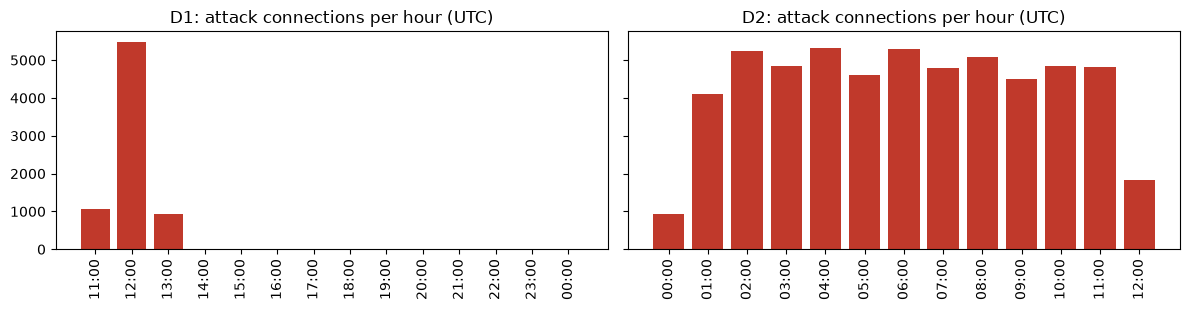

In [8]:
unsw["hour"] = pd.to_datetime(unsw.ts, unit="s").dt.floor("h")
hours = {d: f"{(g.ts.max() - g.ts.min()) / 3600:.1f} h" for d, g in unsw.groupby("day")}
day1_gt = gt[gt.t0 < 1423000000]
print("Hours covered by the logs:", hours)
print("Day 1 attacks in the ground truth:", pd.to_datetime(day1_gt.t0.min(), unit="s"), "to", pd.to_datetime(day1_gt.t1.max(), unit="s"))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2), sharey=True)
for ax, (day, g) in zip(axes, unsw.groupby("day")):
    per_hour = g[g.label == 1].groupby("hour").size().reindex(sorted(g.hour.unique()), fill_value=0)
    ax.bar(range(len(per_hour)), per_hour.to_numpy(), color="#c0392b")
    ax.set_xticks(range(len(per_hour)), [t.strftime("%H:%M") for t in per_hour.index], rotation=90)
    ax.set_title(f"{day}: attack connections per hour (UTC)")
plt.tight_layout()
plt.show()

**Verdict: confirmed.**
- The logs cover about 25 hours in total, not the paper's 31.
- On Day 1, attacks stop at 13:47, followed by about 10.5 hours with none. This contradicts Lanvin et al. Day 2 has attacks in every hour.
- The chart's Day 1 attacks end at 13:10 because the missing log (part 3) covers 13:10–13:52.

### B4. Normal traffic doesn't behave like a real network's

**Claim:**
- 97.6% of normal connections come from 10 hosts.
- In a typical minute, each makes about 129 connections to 58 ports, while an attacker makes about 17 to 7.
- Only 0.6% of normal connections go unanswered, against 19% of attacks.
- Normal connections are very short.
- All attacks come from four addresses, but 39% of those addresses' connections are normal.

In [9]:
normal, attack = unsw[unsw.label == 0], unsw[unsw.label == 1]
top10 = normal.src_ip.value_counts().head(10).index
unsw["minute"] = unsw.ts // 60

def per_minute(df):
    m = df.groupby(["src_ip", "minute"]).agg(conns=("ts", "size"), ports=("dst_port", "nunique")).median()
    return f"{m.conns:.0f} connections to {m.ports:.0f} ports"

attackers = attack.src_ip.unique()
pd.DataFrame({
    "Normal": {
        "Share from the top 10 hosts": pct(normal.src_ip.isin(top10).mean()),
        "Typical host, per minute": per_minute(unsw[(unsw.label == 0) & unsw.src_ip.isin(top10)]),
        "Unanswered connections (S0)": pct((normal.conn_state == "S0").mean()),
        "Typical duration": f"{normal.duration.median():.3f} s",
    },
    "Attack": {
        "Share from the top 10 hosts": f"all from {len(attackers)} addresses",
        "Typical host, per minute": per_minute(unsw[unsw.label == 1]),
        "Unanswered connections (S0)": pct((attack.conn_state == "S0").mean()),
        "Typical duration": f"{attack.duration.median():.3f} s",
    },
})

,Normal,Attack
Share from the top 10 hosts,97.6%,all from 4 addresses
"Typical host, per minute",129 connections to 58 ports,17 connections to 7 ports
Unanswered connections (S0),0.6%,18.8%
Typical duration,0.027 s,0.623 s


In [10]:
print("Attacker addresses:", sorted(attackers))
print("Share of their connections labelled normal:", pct(1 - unsw[unsw.src_ip.isin(attackers)].label.mean()))

Attacker addresses: ['175.45.176.0', '175.45.176.1', '175.45.176.2', '175.45.176.3']
Share of their connections labelled normal: 39.2%


**Verdict: confirmed.** Ten hosts produce almost all normal traffic, each far busier than an attacker. Almost no normal connection fails, and normal connections are much shorter than attacks. Whether these differences act as shortcuts for a model is tested in Notebook 02 (experiment 3).

## Part C: Other datasets

### C1. UWF-ZeekData: normal traffic is nearly idle, and recorded in different weeks from attacks

**Claim:**
- 92–99% of normal connections are DNS.
- In the 2024 releases, every normal TCP connection carried no data.
- Normal and attack traffic were mostly recorded in different weeks.

In [11]:
import glob

rows = []
for name in ["UWF-ZeekData24", "UWF-ZeekDataFall24-2", "UWF-ZeekDataSum25-1", "UWF-ZeekDataSum25-2"]:
    weeks = []
    for f in sorted(glob.glob(str(DATASETS_DIR / "uwf_zeek" / name / "parquet" / "*" / "*.parquet"))):
        w = pd.read_parquet(f, columns=["proto", "service", "orig_bytes", "resp_bytes", "label_binary"])
        w["week"] = f.split("/")[-2]
        weeks.append(w)
    d = pd.concat(weeks)
    d = d[d.label_binary != "Duplicate"]
    n = d[d.label_binary == "False"]
    tcp = n[n.proto == "tcp"]
    attack_share = d.groupby("week").label_binary.apply(lambda s: (s == "True").mean())
    rows.append({
        "Release": name,
        "Normal that is DNS": pct((n.service == "dns").mean()),
        "Normal TCP with no data": pct(((tcp.orig_bytes.fillna(0) + tcp.resp_bytes.fillna(0)) == 0).mean()),
        "Weeks": len(attack_share),
        "Weeks that are at least 99% one kind": int(((attack_share <= 0.01) | (attack_share >= 0.99)).sum()),
    })
pd.DataFrame(rows).set_index("Release")

,Normal that is DNS,Normal TCP with no data,Weeks,Weeks that are at least 99% one kind
Release,,,,
UWF-ZeekData24,91.8%,100.0%,7,7
UWF-ZeekDataFall24-2,91.9%,100.0%,9,9
UWF-ZeekDataSum25-1,99.0%,0.0%,9,9
UWF-ZeekDataSum25-2,98.5%,10.0%,4,3


**Verdict: confirmed.**
- 92–99% of normal connections are DNS in every release.
- In both 2024 releases, every normal TCP connection carried no data. The 2025 releases differ, so the report's claim is correctly limited to 2024.
- In 28 of the 29 weeks, at least 99% of the traffic is one kind: normal or attack. So the date alone almost gives the label away.

### C2. CIC-IDS2017: the published labels miss the infiltration port scan

**Claim:** During Thursday's infiltration, the infected machine (192.168.10.8) port-scans the internal network. The published labels mark this scan as normal [Lanvin et al.; Liu et al.]. Also, attacks pass through one firewall address (172.16.0.1).

*This uses the HuggingFace mirror, with the published CSV labels joined onto Zeek connections. The scan flows are identified from UNB's attack schedule.*

In [12]:
cic = load_cic2017_zeek(with_features=False)
scan = cic[cic.attack_type == "Infiltration - Portscan"]
csv_attacks = cic[cic.label_csv == 1]
pd.DataFrame({
    "Value": {
        "Scan connections (192.168.10.8 to internal hosts, 14:33-15:46)": f"{len(scan):,}",
        "...of which the published labels call an attack": f"{int(scan.label_csv.sum()):,}",
        "Published attack connections involving 172.16.0.1": pct(((csv_attacks.src_ip == "172.16.0.1") | (csv_attacks.dst_ip == "172.16.0.1")).mean()),
    }
})

,Value
"Scan connections (192.168.10.8 to internal hosts, 14:33-15:46)","73,828"
...of which the published labels call an attack,0
Published attack connections involving 172.16.0.1,98.9%


**Verdict: confirmed** (on mirror data). None of the tens of thousands of scan connections is labelled as an attack in the published labels. Almost every published attack connection involves the firewall address 172.16.0.1.

## Not tested here

- **TON_IoT:** our copy of the CSV doesn't match the official file's row counts, so checks on it wouldn't be reliable.
- **AIT-LDSv2:** our Zeek file was built only from the attacker's captures. The server captures in the official download haven't been converted yet.

## Summary

| # | Claim | Verdict |
|---|---|---|
| A1 | One TTL value separates attacks from normal traffic | Confirmed |
| A2 | 42% of training and 34.5% of testing rows are duplicates | Confirmed (identical features) |
| A3 | The training and testing CSVs don't match | Confirmed |
| A4 | "Generic" is mostly DNS | Confirmed |
| B1 | Zeek logs are standard, but one part is missing and one broken | Confirmed |
| B2 | Labelling works, but many UDP attacks aren't found | Confirmed |
| B3 | Shorter capture than described; Day 1 has an attack-free period | Confirmed |
| B4 | Normal traffic comes from 10 busy hosts and almost never fails | Confirmed |
| C1 | UWF normal traffic is idle and recorded in separate weeks | Confirmed |
| C2 | CIC labels miss the infiltration port scan | Confirmed (mirror data) |